# CP1 · Ablasi cabang attention FUSegNet

Tiga model: baseline P-scSE penuh, additive-only, maxout-only. Stage 0–3 diubah; stage terakhir tetap shorted. Notebook menyimpan seluruh output, termasuk contoh prediksi.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/baseline.json').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from build_ablation_analysis import load_comparison, display_table, plot_curves, plot_categories, plot_errors, plot_examples
from cp1_analysis import configure_style
%matplotlib inline
configure_style()
c = load_comparison(ROOT / 'outputs/ablations/cp1-attention-01')
def table(frame):
    display(HTML(frame.to_html(index=False, border=0, na_rep='—', float_format=lambda x: f'{x:.4f}')))
print('1.206 pasangan mask sudah diverifikasi; tidak ada training atau inference di notebook ini.')

1.206 pasangan mask sudah diverifikasi; tidak ada training atau inference di notebook ini.


## 1 · Hipotesis dan kontrol

Kombinasi additive/maxout diuji terhadap masing-masing cabang. Split, seed 42, constructor dan bobot awal, pretrained encoder, augmentasi, loss, optimizer, scheduler, aturan checkpoint, early stopping, threshold 0.5, serta evaluator tetap sama. Cabang dorman tetap terdaftar untuk menyamakan inisialisasi; parameter yang dipakai forward berkurang. Baseline test sudah pernah dianalisis; varian dan endpoint dikunci sebelum training baru.

In [2]:
table(c['summary'].query("split == 'validation'")[[
    'model','registered_parameters','forward_called_parameters','training_minutes','peak_cuda_gib'
]])

model,registered_parameters,forward_called_parameters,training_minutes,peak_cuda_gib
P-scSE penuh,70968939,64898248,105.3560,2.2228
Additive-only,70968939,64781798,86.3574,2.1817
Maxout-only,70968939,64781798,220.5976,2.2197


## 2 · Validation dan pemilihan checkpoint

Checkpoint mengikuti kebijakan loss/IoU penulis, bukan pemilihan berdasarkan hasil test atau maksimum metrik lain. F-score pada kurva memakai rata-rata batch.

Model,n,Epoch selesai,Checkpoint,Image Dice (%),Data Dice (%),PFOM (1/0)
P-scSE penuh,124,82,52,82.3374,85.9041,0.7244
Additive-only,124,68,38,80.5803,89.1126,0.7058
Maxout-only,124,176,146,82.5806,91.2689,0.7266


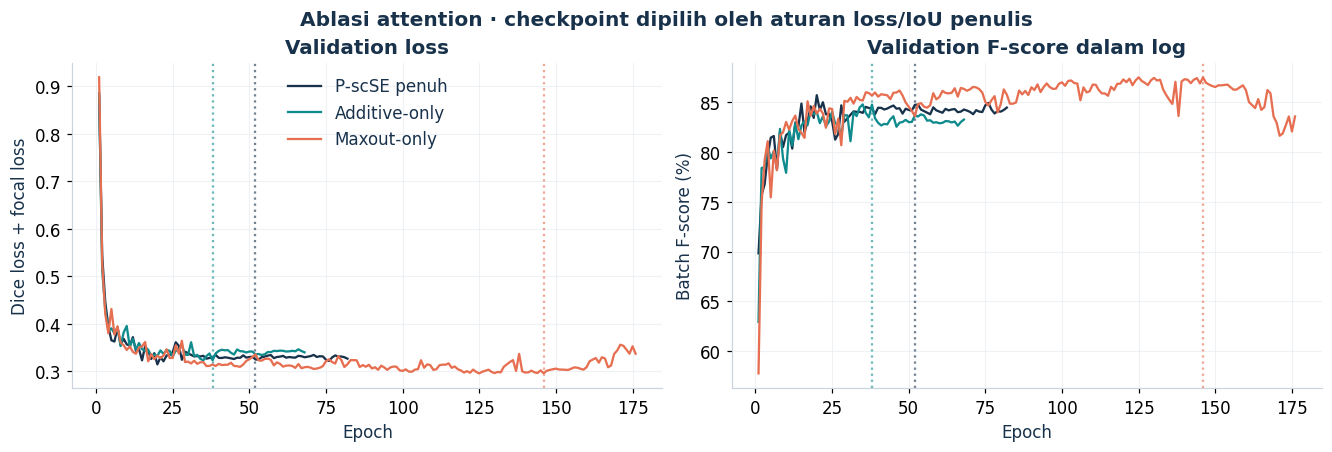

In [3]:
table(display_table(c, 'validation'))
plot_curves(c)
plt.show()

## 3 · Test semua varian

Seluruh varian dilaporkan dengan checkpoint terpilih masing-masing. PFOM utama memakai kebijakan edge kosong 1/0; proxy sentinel 2 terpisah.

In [4]:
table(display_table(c, 'test'))
table(c['summary'].query("split == 'test'")[['model','pfom_positive_gt','pfom_sentinel2_proxy','missed_wounds','empty_gt_fp_images','empty_gt_fp_pixels']])

Model,n,Epoch selesai,Checkpoint,Image Dice (%),Data Dice (%),PFOM (1/0)
P-scSE penuh,278,82,52,86.4196,92.2891,0.7782
Additive-only,278,68,38,84.8133,91.8308,0.7554
Maxout-only,278,176,146,84.6457,92.3452,0.7613


model,pfom_positive_gt,pfom_sentinel2_proxy,missed_wounds,empty_gt_fp_images,empty_gt_fp_pixels
P-scSE penuh,0.7905,0.8933,4,7,3081
Additive-only,0.7701,0.8669,3,8,1561
Maxout-only,0.7803,0.8836,6,9,2076


## 4 · Analisis menurut area GT dan kasus error

C0 berisi GT kosong dan tidak dimasukkan pada grafik kelompok GT positif. Luas memakai kanvas penuh termasuk padding, bukan ukuran fisik luka.

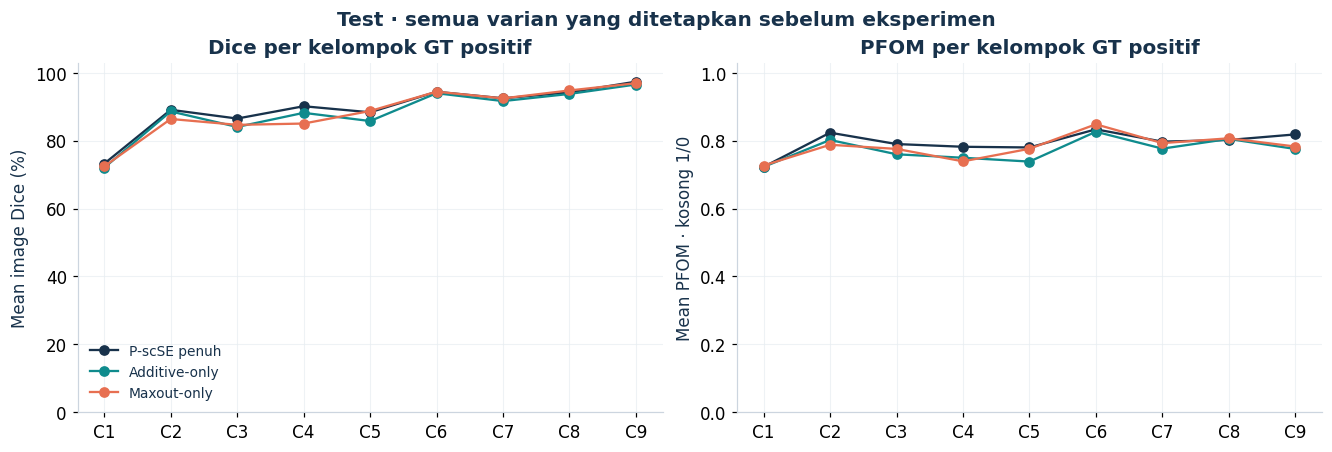

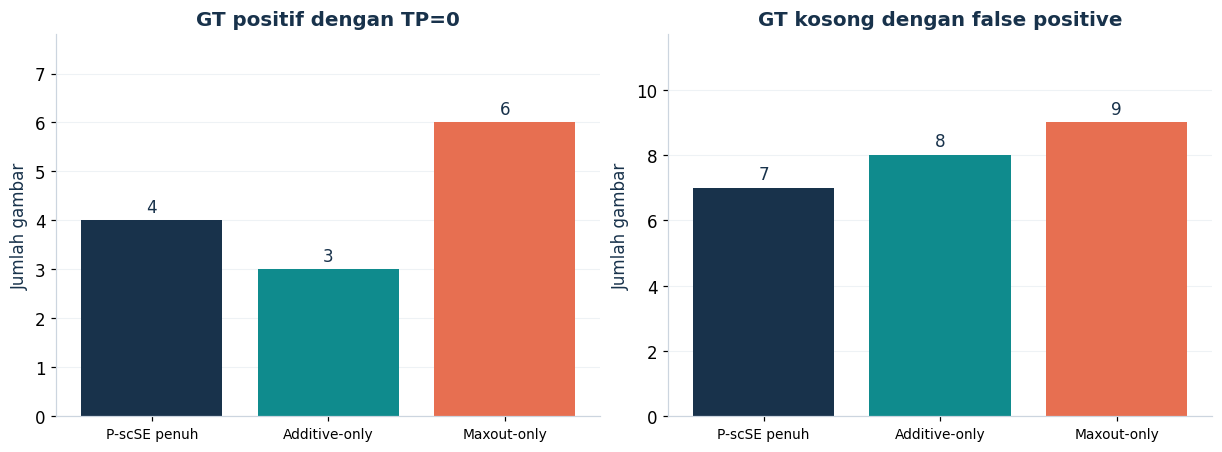

variant,model,category,n,image_dice,data_dice,pfom_mean,pfom_sentinel2_proxy
full,P-scSE penuh,0,17,0.5882,0.0000,0.5882,2.0000
full,P-scSE penuh,1,36,0.7322,0.7788,0.7227,0.8893
full,P-scSE penuh,2,35,0.8907,0.8868,0.8233,0.8233
full,P-scSE penuh,3,37,0.8650,0.8722,0.7899,0.8440
full,P-scSE penuh,4,24,0.9012,0.9035,0.7819,0.7819
full,P-scSE penuh,5,35,0.8834,0.8810,0.7798,0.7798
full,P-scSE penuh,6,29,0.9439,0.9442,0.8332,0.8332
full,P-scSE penuh,7,38,0.9246,0.9291,0.7970,0.7970
full,P-scSE penuh,8,20,0.9421,0.9454,0.8018,0.8018
full,P-scSE penuh,9,7,0.9736,0.9697,0.8183,0.8183


In [5]:
plot_categories(c)
plt.show()
plot_errors(c)
plt.show()
table(c['categories'])

## 5 · Contoh tetap dari baseline

Enam contoh ditetapkan dari dua worst-positive, dua median-positive, dan dua empty-FP baseline sebelum training ablasi. Galeri tidak dipilih berdasarkan hasil varian baru. Crop sama pada seluruh kolom; hijau TP, merah FP, biru FN.

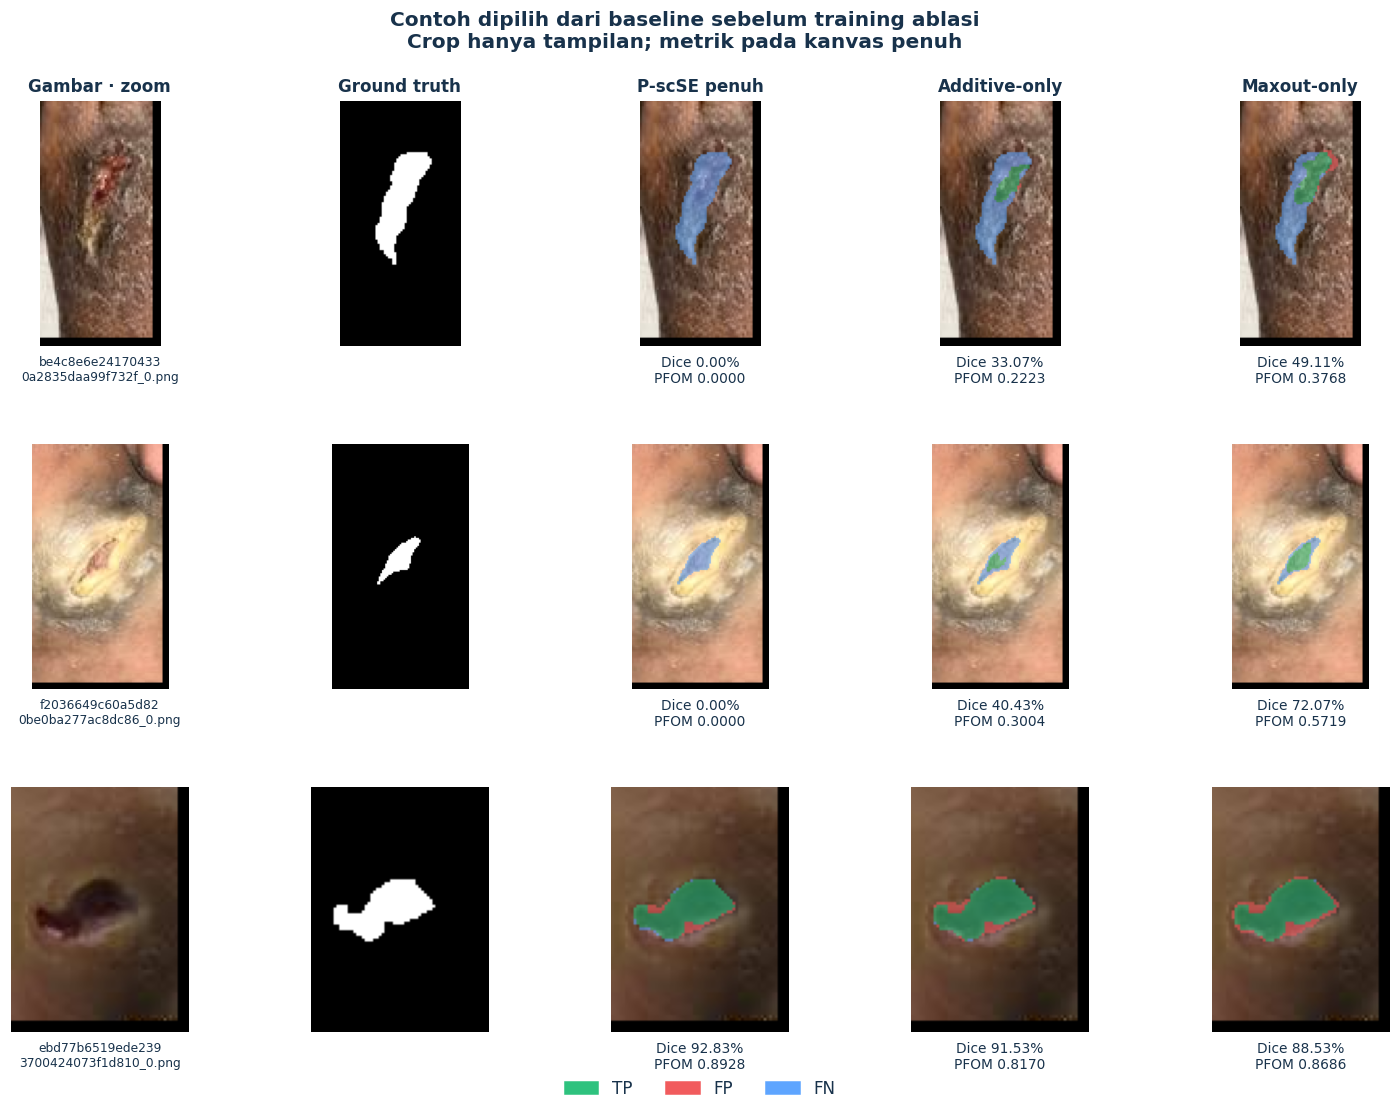

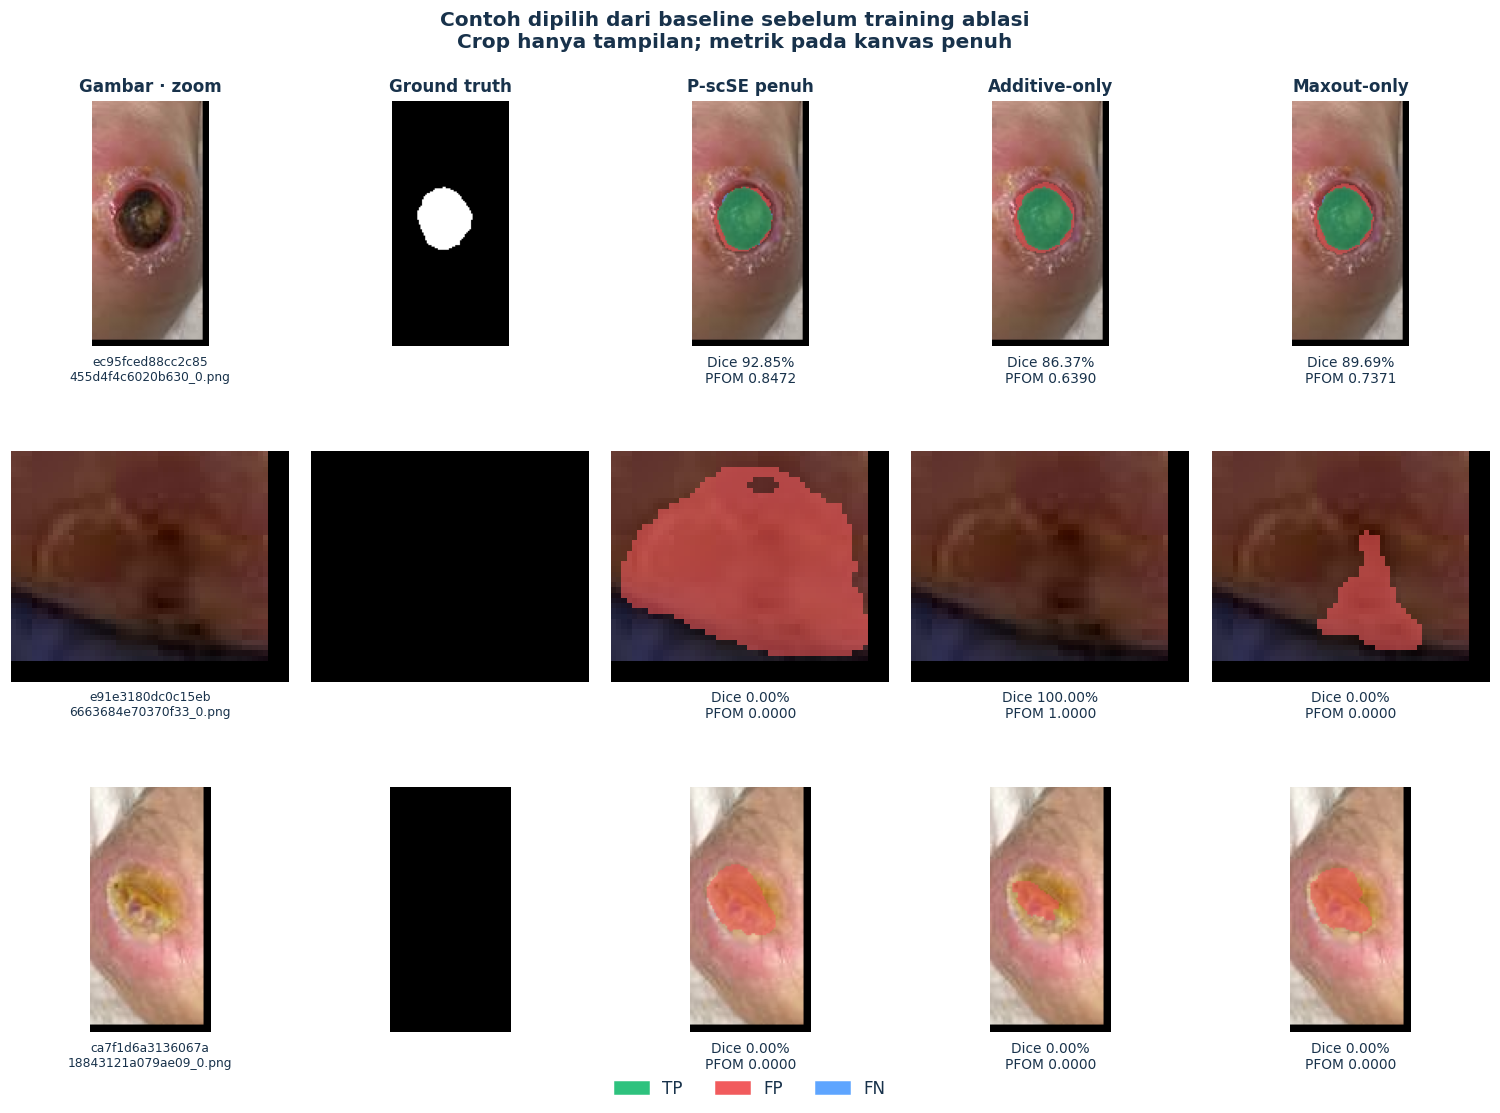

In [6]:
plot_examples(c, 0)
plt.show()
plot_examples(c, 3)
plt.show()

## 6 · Batas interpretasi

Ini satu seed; perbedaan kecil belum mengukur variasi antar-training. Menghapus cabang juga mengurangi parameter aktif dan komputasi. Jumlah/split asli paper belum identik, duplikasi RGB antar-split tetap ada, dan independensi pasien belum terbukti. Setting PFOM lokal terdokumentasi; kesetaraan persis dengan Figure 6 paper belum terverifikasi. Perbandingan ini merupakan ablasi cabang dengan struktur decoder tetap, bukan penggunaan opsi scSE bawaan yang mengubah konvolusi.

## Referensi

Contoh gambar dan GT berasal dari [Chronic Wound / UWM](https://github.com/uwm-bigdata/wound-segmentation/tree/master/data/wound_dataset). Benchmark: [Dhar et al., FUSegNet](https://arxiv.org/abs/2305.02961v2); [kode referensi](https://github.com/mrinal054/FUSegNet). Konfigurasi eksperimen: [protokol ablasi](../docs/attention-ablations.md).

In [7]:
print('Protocol fingerprint:', c['metadata']['protocol_fingerprint'])
print('Initial-state SHA256:', c['metadata']['model_verification']['full_initial_state_sha256'])
print('Diagnostic fixture:', c['metadata']['diagnostic_fixture'])

Protocol fingerprint: 5901c5fa22b7aa7b70777e520ee997b72ba1079ff6d1b07338b6b09a8651773b
Initial-state SHA256: fd3fe8b007a897b5c3a977b8bbafec662fed4bdf6489d8a51a18376a4bb7e031
Diagnostic fixture: False
